<a href="https://colab.research.google.com/github/YASHAS-KING/BIS_LAB/blob/main/Parallel_Cellular_Algorithms_BIS_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Executing Parallel Cellular Algorithm on Device: cuda
PARALLEL CELLULAR ALGORITHM OPTIMIZATION RESULTS
Execution Device       : cuda
Grid Dimensions          : 20 x 20 (400 Active Cells)
Neighborhood Structure   : Moore (8-Connected Torus)
Problem Dimensions       : 10
Max Generations          : 200
Total Execution Time     : 0.9162 Seconds
----------------------------------------------------------------------
Initial Best Fitness     : 90.010132
Final Best Fitness       : 8.122086e+00

Optimal Decision Vector (x*):
[ 0.04348162  0.0586172   0.04890627  0.16193184  0.04602059  0.06443655
 -0.00960945 -0.02460997  0.04862013 -0.00089389]


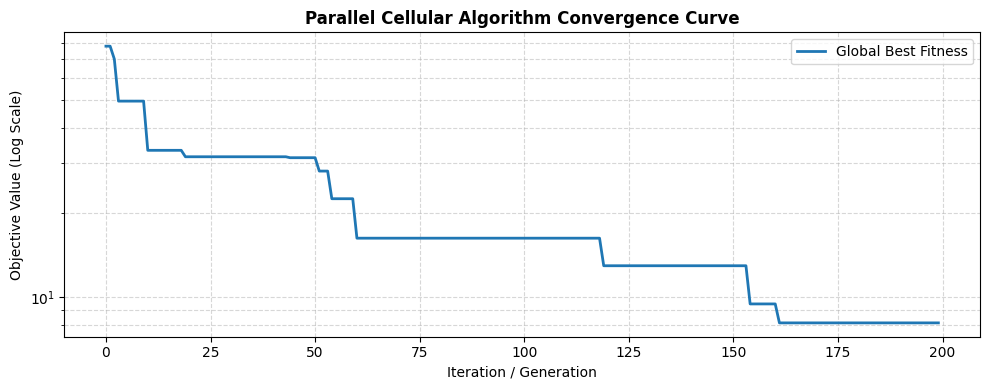

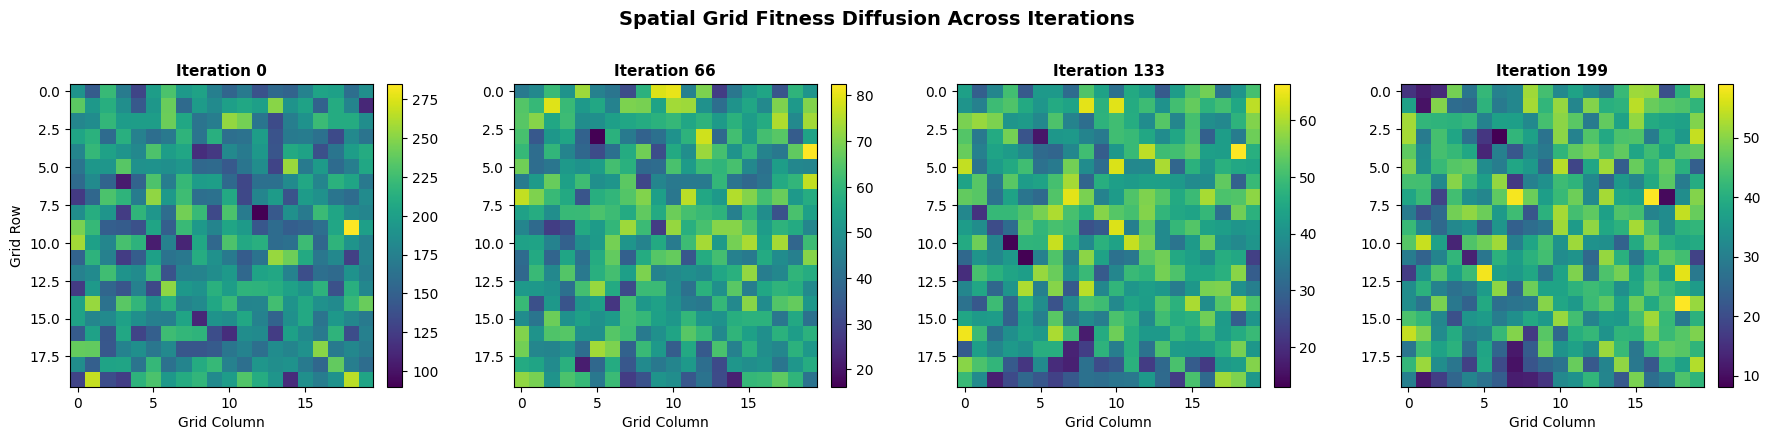

In [ ]:
import time
import torch
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# DEVICE CONFIGURATION
# ==============================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing Parallel Cellular Algorithm on Device: {device}")

# ==============================================================================
# STEP 1: DEFINE OBJECTIVE FUNCTIONS (Batched Tensor Input)
# ==============================================================================
def sphere_function(x: torch.Tensor) -> torch.Tensor:
    """
    Unimodal Sphere Benchmark: f(x) = sum(x_i^2)
    Global Minimum: f(0, ..., 0) = 0.0
    """
    return torch.sum(x**2, dim=-1)

def rastrigin_function(x: torch.Tensor) -> torch.Tensor:
    """
    Multimodal Rastrigin Benchmark: f(x) = 10d + sum(x_i^2 - 10*cos(2*pi*x_i))
    Global Minimum: f(0, ..., 0) = 0.0
    """
    d = x.shape[-1]
    return 10 * d + torch.sum(x**2 - 10 * torch.cos(2 * torch.pi * x), dim=-1)

# ==============================================================================
# STEPS 2-7: PARALLEL CELLULAR ALGORITHM ENGINE
# ==============================================================================
class ParallelCellularAlgorithm:
    def __init__(
        self,
        objective_func,
        dim: int = 10,
        bounds: tuple = (-5.12, 5.12),
        grid_shape: tuple = (20, 20),
        max_iter: int = 200,
        F: float = 0.5,
        CR: float = 0.8
    ):
        self.func = objective_func
        self.dim = dim
        self.bounds = bounds
        self.R, self.C = grid_shape
        self.max_iter = max_iter
        self.F = F
        self.CR = CR

        # 8-Directional Offsets for Moore Neighborhood
        self.offsets = [
            (-1, 0), (1, 0), (0, -1), (0, 1),   # von Neumann (N, S, W, E)
            (-1, -1), (-1, 1), (1, -1), (1, 1)  # Diagonals (NW, NE, SW, SE)
        ]

    def optimize(self):
        start_time = time.time()

        # STEP 3: INITIALIZE POPULATION GRID (R x C x dim)
        lower, upper = self.bounds
        P = torch.rand(self.R, self.C, self.dim, device=device) * (upper - lower) + lower

        # STEP 4: EVALUATE INITIAL FITNESS GRID (R x C)
        F_grid = self.func(P)

        # Track initial metrics
        initial_best_f = torch.min(F_grid).item()
        history_best_f = []
        heatmap_snapshots = {}

        snapshot_intervals = [0, self.max_iter // 3, (2 * self.max_iter) // 3, self.max_iter - 1]

        # Global best tracking
        min_flat_idx = torch.argmin(F_grid)
        best_r, best_c = divmod(min_flat_idx.item(), self.C)
        global_best_f = F_grid[best_r, best_c].item()
        global_best_x = P[best_r, best_c].clone()

        # STEP 5 & 6: ITERATIVE STATE UPDATES & SYNCHRONIZATION
        for iteration in range(self.max_iter):
            # Capture spatial grid snapshot for visualization
            if iteration in snapshot_intervals:
                heatmap_snapshots[iteration] = F_grid.cpu().numpy().copy()

            # Construct Moore Neighborhood Tensors via Toroidal Rolls
            # Tensor Shape: (9, R, C, dim) where index 0 is center cell
            stacked_P = torch.stack(
                [P] + [torch.roll(P, shifts=off, dims=(0, 1)) for off in self.offsets],
                dim=0
            )
            stacked_F = torch.stack(
                [F_grid] + [torch.roll(F_grid, shifts=off, dims=(0, 1)) for off in self.offsets],
                dim=0
            )

            # Find Local Best Neighbor per Cell
            local_best_indices = torch.argmin(stacked_F, dim=0) # Shape: (R, C)
            local_best_P = torch.gather(
                stacked_P, 0, local_best_indices.unsqueeze(0).unsqueeze(-1).expand(1, self.R, self.C, self.dim)
            ).squeeze(0)

            # Select 2 Random Distinct Neighbors per Cell from the 8 Moore Neighbors
            neighbors_P_only = stacked_P[1:] # Shape: (8, R, C, dim)
            idx1 = torch.randint(0, 8, (self.R, self.C), device=device)
            idx2 = (idx1 + torch.randint(1, 8, (self.R, self.C), device=device)) % 8

            r1_P = torch.gather(neighbors_P_only, 0, idx1.unsqueeze(0).unsqueeze(-1).expand(1, self.R, self.C, self.dim)).squeeze(0)
            r2_P = torch.gather(neighbors_P_only, 0, idx2.unsqueeze(0).unsqueeze(-1).expand(1, self.R, self.C, self.dim)).squeeze(0)

            # Generate Trial State (Mutation: Target-to-Local-Best Scheme)
            V = P + self.F * (local_best_P - P) + self.F * (r1_P - r2_P)

            # Apply Binomial Crossover
            crossover_mask = torch.rand(self.R, self.C, self.dim, device=device) < self.CR
            j_rand = torch.randint(0, self.dim, (self.R, self.C), device=device)
            crossover_mask.scatter_(-1, j_rand.unsqueeze(-1), True) # Ensure >= 1 dimension updates

            Trial_P = torch.where(crossover_mask, V, P)
            Trial_P = torch.clamp(Trial_P, lower, upper)
            Trial_F = self.func(Trial_P)

            # Local Selection (Elitist Replacement)
            improved_mask = Trial_F <= F_grid
            P = torch.where(improved_mask.unsqueeze(-1), Trial_P, P)
            F_grid = torch.where(improved_mask, Trial_F, F_grid)

            # Update Global Best
            current_min_val, current_min_idx = torch.min(F_grid.view(-1), dim=0)
            if current_min_val.item() < global_best_f:
                global_best_f = current_min_val.item()
                cr, cc = divmod(current_min_idx.item(), self.C)
                global_best_x = P[cr, cc].clone()

            history_best_f.append(global_best_f)

        # Final Snapshot
        heatmap_snapshots[self.max_iter - 1] = F_grid.cpu().numpy().copy()
        elapsed_time = time.time() - start_time

        # STEP 7: OUTPUT METRICS & RESULTS
        print("=" * 70)
        print("PARALLEL CELLULAR ALGORITHM OPTIMIZATION RESULTS")
        print("=" * 70)
        print(f"Execution Device       : {device}")
        print(f"Grid Dimensions          : {self.R} x {self.C} ({self.R * self.C} Active Cells)")
        print(f"Neighborhood Structure   : Moore (8-Connected Torus)")
        print(f"Problem Dimensions       : {self.dim}")
        print(f"Max Generations          : {self.max_iter}")
        print(f"Total Execution Time     : {elapsed_time:.4f} Seconds")
        print("-" * 70)
        print(f"Initial Best Fitness     : {initial_best_f:.6f}")
        print(f"Final Best Fitness       : {global_best_f:.6e}")
        print("\nOptimal Decision Vector (x*):")
        print(global_best_x.cpu().numpy())
        print("=" * 70)

        return history_best_f, heatmap_snapshots

# ==============================================================================
# EXECUTION & VISUALIZATION PIPELINE
# ==============================================================================
if __name__ == "__main__":
    # Choose Objective Function: sphere_function OR rastrigin_function
    target_func = rastrigin_function
    bounds = (-5.12, 5.12)
    max_generations = 200

    pca = ParallelCellularAlgorithm(
        objective_func=target_func,
        dim=10,
        bounds=bounds,
        grid_shape=(20, 20),
        max_iter=max_generations,
        F=0.5,
        CR=0.8
    )

    history, heatmaps = pca.optimize()

    # 1. Plot Convergence History
    plt.figure(figsize=(10, 4))
    plt.plot(history, color='#1f77b4', linewidth=2, label='Global Best Fitness')
    plt.yscale('log')
    plt.title('Parallel Cellular Algorithm Convergence Curve', fontsize=12, fontweight='bold')
    plt.xlabel('Iteration / Generation', fontsize=10)
    plt.ylabel('Objective Value (Log Scale)', fontsize=10)
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 2. Plot Spatial Grid Diffusion Heatmaps
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    snapshot_keys = sorted(heatmaps.keys())

    for idx, key in enumerate(snapshot_keys):
        im = axes[idx].imshow(heatmaps[key], cmap='viridis', origin='upper')
        axes[idx].set_title(f'Iteration {key}', fontsize=11, fontweight='bold')
        axes[idx].set_xlabel('Grid Column')
        if idx == 0:
            axes[idx].set_ylabel('Grid Row')
        fig.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)

    plt.suptitle('Spatial Grid Fitness Diffusion Across Iterations', fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()